# Figure S3 - Local conformational properties of DDX4<sup>[1-245]</sup> from all-atom simulations

**What the figure shows.** Three stacked per-residue panels, all sharing the DDX4 NTD sequence as the x-axis, that together ask a single question: *does this disordered protein behave like a random coil at the local level?*

* **(A) Secondary structure.** The fraction of conformations in which DSSP assigns each residue to a helical or an extended (beta-strand/sheet) conformation, across 20 independent simulations. Helicity is drawn upwards in blue, beta-sheet downwards in red, with a violin per residue showing the spread across replicas and a line through the means.
* **(B) Backbone dihedrals.** The Hellinger distance between each residue's phi (purple) or psi (green) angle distribution and the same residue's distribution in a self-avoiding random coil (SARC) simulation. Zero means the two distributions are identical; one means they do not overlap at all. Bigger values mean *less* random-coil-like.
* **(C) Local radius of gyration.** The radius of gyration of a sliding 10-residue window, divided by the same quantity from the SARC simulation. Values near 1 are random-coil-like; values below 1 mean local intramolecular interactions have compacted that stretch of chain.

**The reference ensemble.** Panels B and C are both ratios against a self-avoiding random coil, and that comparison is what makes them interpretable. The SARC ensemble uses the identical all-atom representation and the same simulation engine, but with all attractive interactions switched off - so the chain cannot overlap itself, but has no reason to prefer any conformation. It is therefore the most conformationally heterogeneous ensemble this sequence can have, and any deviation from it is a genuine sequence-encoded conformational bias rather than a trivial consequence of chain connectivity.

**What it tells you.** DDX4<sup>[1-245]</sup> is disordered - there is no persistent secondary structure anywhere in the chain - but it is not a featureless random coil. There are several regions of transient helicity, the dihedral distributions deviate measurably from SARC behaviour along the whole sequence, and local segments are consistently more compact than the SARC reference. This supports the paper's UV resonance Raman result (Figure 2), where the amide III band at 1,300 cm<sup>-1</sup> is incompatible with a purely random-coil ensemble.

**How it is made.** All-atom Monte Carlo simulations were run in CAMPARI with the ABSINTH implicit solvent model; the analysis here is done with [SOURSOP](https://soursop.readthedocs.io/). Panel A reads precomputed per-replica DSSP occupancies; panels B and C are computed directly from the pooled trajectories in this notebook.

## What is in this directory

| path | contents |
|------|----------|
| `data/dssp/` | per-replica DSSP helical (`DSSP_H.csv`) and extended (`DSSP_E.csv`) occupancies, 10 helical-start and 10 coil-start replicas |
| `data/README.md` | provenance of everything used here |
| `figures/` | output; the notebook writes one PDF and PNG per panel |

The two CAMPARI trajectories are large (~750 MB together) and live in the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git**. See `../data/README.md` for what belongs there and how to obtain it. Everything else this notebook needs is in this directory.

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from soursop.sstrajectory import SSTrajectory
from soursop.sssampling import hellinger_distance
from tqdm.auto import tqdm

In [2]:
import os

# Panel A data lives here; panels B and C need the large trajectories, which
# live in the shared (git-ignored) data directory at the root of perets_2025.
DSSP_DIR = 'data/dssp'
TRAJ_DIR = os.environ.get('PERETS_DATA_DIR', '../data')

os.makedirs('figures', exist_ok=True)

CAMPARI_NTD = os.path.join(TRAJ_DIR, 'campari', 'ddx4_ntd')
CAMPARI_EV = os.path.join(TRAJ_DIR, 'campari', 'ev')

for label, path in [('DDX4 NTD', CAMPARI_NTD), ('SARC (EV)', CAMPARI_EV)]:
    status = 'found' if os.path.isfile(os.path.join(path, 'full.xtc')) else 'MISSING - see ../data/README.md'
    print(f'{label:<10} {path}  [{status}]')

DDX4 NTD   ../data/campari/ddx4_ntd  [found]
SARC (EV)  ../data/campari/ev  [found]


## Panel A - secondary structure

CAMPARI writes, for each simulation, the fraction of sampled conformations in which each residue is assigned to a given DSSP class. We read the helical (`DSSP_H`) and extended (`DSSP_E`) occupancies for all 20 replicas: 10 started from a fully helical conformation and 10 from a random coil. Starting from both extremes is a sampling control - if the two sets converge on the same answer, the result does not depend on where the simulation started.

Each array is one value per residue, so stacking 20 of them gives a (20, 245) matrix per DSSP class.

In [3]:
dssp_h = []
dssp_e = []

for prefix in ['helical_start', 'coil_start']:
    for replica in range(1, 11):
        dssp_h.append(np.loadtxt(f'{DSSP_DIR}/{prefix}/{replica}/DSSP_H.csv'))
        dssp_e.append(np.loadtxt(f'{DSSP_DIR}/{prefix}/{replica}/DSSP_E.csv'))

dssp_h = np.array(dssp_h)
dssp_e = np.array(dssp_e)

print(f'helicity  : {dssp_h.shape} (replicas, residues), mean occupancy {dssp_h.mean():.3f}')
print(f'beta-sheet: {dssp_e.shape} (replicas, residues), mean occupancy {dssp_e.mean():.3f}')
print(f'peak mean helicity {dssp_h.mean(axis=0).max():.2f} at residue {dssp_h.mean(axis=0).argmax() + 1}')

helicity  : (20, 245) (replicas, residues), mean occupancy 0.049
beta-sheet: (20, 245) (replicas, residues), mean occupancy 0.010
peak mean helicity 0.53 at residue 175


Helicity is drawn upwards and beta-sheet downwards (by negating it) so the two can share an axis without overlapping. The violins show the spread across the 20 replicas; the solid line is the mean.

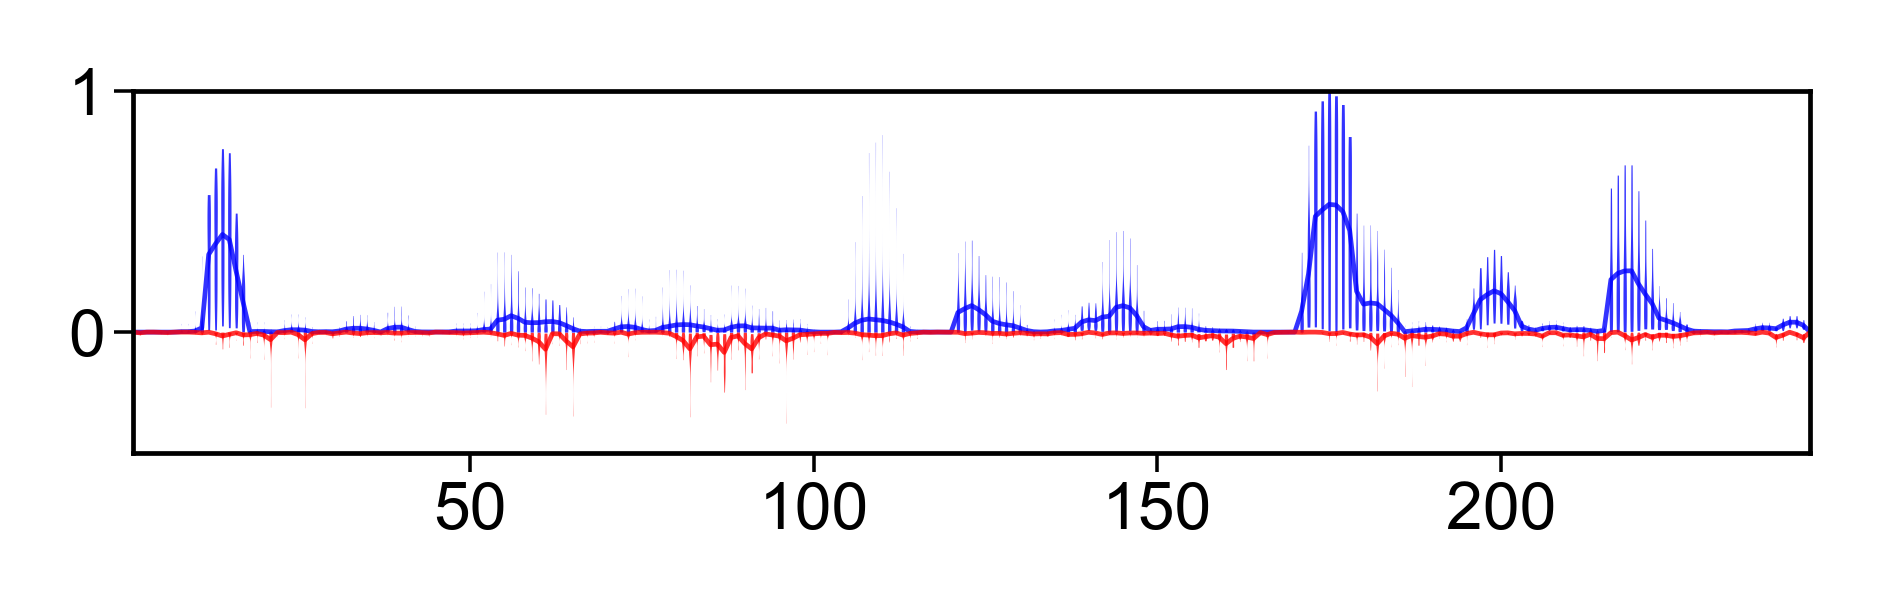

In [4]:
plt.figure(figsize=(3, 1), dpi=340)
ax = plt.gca()

for values, colour, sign in [(dssp_h, 'blue', 1), (dssp_e, 'red', -1)]:
    parts = ax.violinplot(sign * values, showmeans=False, showextrema=False, showmedians=False)
    for body in parts['bodies']:
        body.set_alpha(0.8)
        body.set_facecolor(colour)
        body.set_edgecolor(colour)
        body.set_linewidth(0)

    ax.plot(np.arange(1, values.shape[1] + 1), sign * np.mean(values, axis=0),
            color=colour, linewidth=0.5, alpha=0.8)

ax.set_ylim([-0.5, 1])
ax.set_xlim([1, 245])
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig('figures/figure_S3A_local_secondary.pdf')
plt.savefig('figures/figure_S3A_local_secondary.png', dpi=340)
plt.show()

## Loading the trajectories for panels B and C

Both remaining panels compare the real ensemble against the self-avoiding random coil. Each `SSTrajectory` here is the pooled set of conformations across all replicas for that condition.

This is the slow step in the notebook - together the two trajectories are about 750 MB - but everything after it is fast.

In [5]:
NTD = SSTrajectory(f'{CAMPARI_NTD}/full.xtc', f'{CAMPARI_NTD}/full.pdb').proteinTrajectoryList[0]
EV = SSTrajectory(f'{CAMPARI_EV}/full.xtc', f'{CAMPARI_EV}/full.pdb').proteinTrajectoryList[0]

print(f'DDX4 NTD  : {NTD.n_frames:,} conformers, {NTD.n_residues} residues')
print(f'SARC (EV) : {EV.n_frames:,} conformers, {EV.n_residues} residues')

DDX4 NTD  : 25,000 conformers, 247 residues
SARC (EV) : 28,837 conformers, 247 residues


## Panel B - backbone dihedral distributions versus a random coil

For every residue we histogram its backbone dihedral angle over the whole ensemble, do the same for the SARC ensemble, and measure how different the two histograms are with the Hellinger distance (`soursop.sssampling.hellinger_distance`). The Hellinger distance is bounded on [0, 1]: 0 means the two distributions are identical, 1 means they share no support at all. Larger values therefore mean the residue is *less* random-coil-like.

Angles are shifted by 180 degrees onto [0, 360) and binned in 60-degree bins. The bin width matters - too fine and you measure sampling noise, too coarse and real differences wash out - and 60 degrees is wide enough to be robust at this sampling depth while still separating the major basins of the Ramachandran map.

The absolute values here are small (all below 0.06). That is the point: these are subtle local biases, not folded structure.

In [6]:
def dihedral_hellinger(ensemble_1, ensemble_2, angle='phi', binsize=60):
    """
    Per-residue Hellinger distance between two ensembles' dihedral distributions.

    For each residue the requested backbone dihedral is histogrammed over all
    frames in each ensemble, and the Hellinger distance between the resulting
    normalised distributions is returned. The distance is bounded on [0, 1],
    where 0 means the distributions are identical and 1 means they do not
    overlap at all.

    Parameters
    ----------
    ensemble_1 : soursop.ssprotein.SSProtein
        First ensemble; the one being characterised.

    ensemble_2 : soursop.ssprotein.SSProtein
        Second ensemble; here the self-avoiding random coil reference.

    angle : str
        Backbone dihedral to compare, passed through to
        `SSProtein.get_angles`. One of 'phi', 'psi' or 'omega'.
        Default = 'phi'.

    binsize : int
        Width of the histogram bins in degrees. Default = 60.

    Returns
    -------
    numpy.ndarray
        One Hellinger distance per residue.
    """

    angles_1 = ensemble_1.get_angles(angle)[1]
    angles_2 = ensemble_2.get_angles(angle)[1]

    if angles_1.shape[0] != angles_2.shape[0]:
        raise ValueError('Mismatch in number of residues between the two ensembles')

    bins = np.arange(0, 360 + binsize, binsize)

    distances = []
    for residue in tqdm(range(angles_1.shape[0])):
        # shift from [-180, 180) onto [0, 360) before histogramming
        p, _ = np.histogram(angles_1[residue] + 180, bins=bins, density=True)
        q, _ = np.histogram(angles_2[residue] + 180, bins=bins, density=True)
        distances.append(hellinger_distance(p, q))

    return np.array(distances)

In [7]:
phi_hellinger = dihedral_hellinger(NTD, EV, 'phi')
psi_hellinger = dihedral_hellinger(NTD, EV, 'psi')

print(f'phi : mean {phi_hellinger.mean():.4f}, max {phi_hellinger.max():.4f} at residue {phi_hellinger.argmax() + 1}')
print(f'psi : mean {psi_hellinger.mean():.4f}, max {psi_hellinger.max():.4f} at residue {psi_hellinger.argmax() + 1}')

  0%|          | 0/245 [00:00<?, ?it/s]

  0%|          | 0/245 [00:00<?, ?it/s]

phi : mean 0.0260, max 0.0523 at residue 173
psi : mean 0.0202, max 0.0549 at residue 177


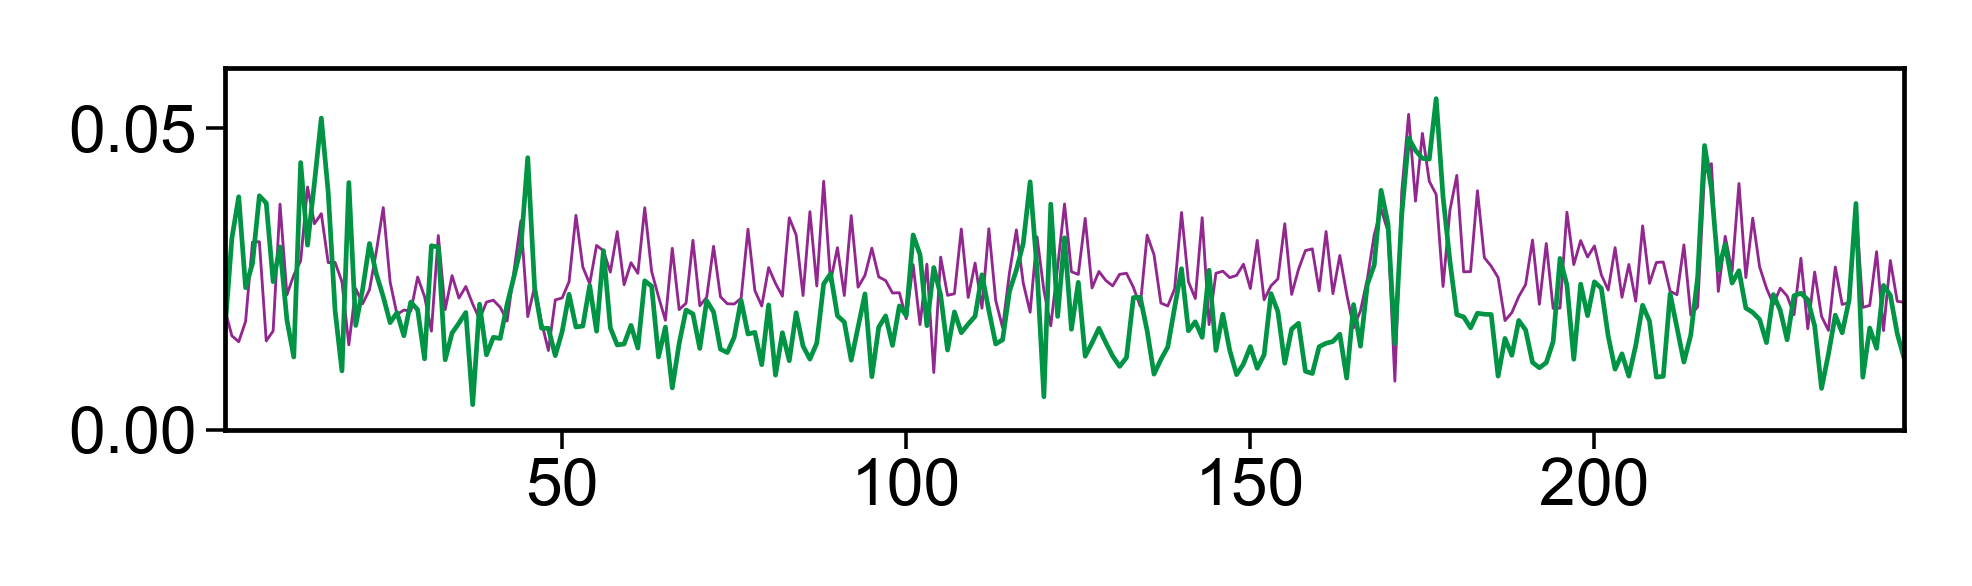

In [8]:
plt.figure(figsize=(3, 1), dpi=340)
ax = plt.gca()

residues = np.arange(1, len(phi_hellinger) + 1)
ax.plot(residues, phi_hellinger, lw=0.3, color='#92278F')   # phi, purple
ax.plot(residues, psi_hellinger, lw=0.5, color='#009444')   # psi, green

ax.set_ylim([0, 0.06])
ax.set_xlim([1, 245])
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig('figures/figure_S3B_coil_hellinger.pdf')
plt.savefig('figures/figure_S3B_coil_hellinger.png', dpi=340)
plt.show()

## Panel C - local compaction versus a random coil

Panel B looks at single residues; this panel asks the same question over a slightly longer length scale. We slide a 10-residue window along the chain and compute the radius of gyration of just that window, in both the real and the SARC ensembles, then take the ratio.

A ratio of 1 means that stretch of chain is as expanded as it would be with no attractive interactions at all. Below 1 means local intramolecular interactions are pulling it in. Because the window is 10 residues wide, each value is plotted at the centre of its window rather than at its start.

In [9]:
WINDOW_SIZE = 10

# n_residues counts the two terminal caps (ACE/NME) that CAMPARI adds; the
# DDX4[1-245] construct itself is 245 residues, giving 236 windows
N_RESIDUES = NTD.n_residues - 2

sliding_rg_real = []
sliding_rg_ev = []

for start in tqdm(range(0, (N_RESIDUES + 1) - WINDOW_SIZE)):
    sliding_rg_real.append(np.mean(NTD.get_radius_of_gyration(start, start + WINDOW_SIZE)))
    sliding_rg_ev.append(np.mean(EV.get_radius_of_gyration(start, start + WINDOW_SIZE)))

local_rg_ratio = np.array(sliding_rg_real) / np.array(sliding_rg_ev)

print(f'{len(local_rg_ratio)} windows')
print(f'mean ratio {local_rg_ratio.mean():.3f}, min {local_rg_ratio.min():.3f} '
      f'at window centred on residue {local_rg_ratio.argmin() + 1 + WINDOW_SIZE // 2}')

  0%|          | 0/236 [00:00<?, ?it/s]

236 windows
mean ratio 0.900, min 0.768 at window centred on residue 177


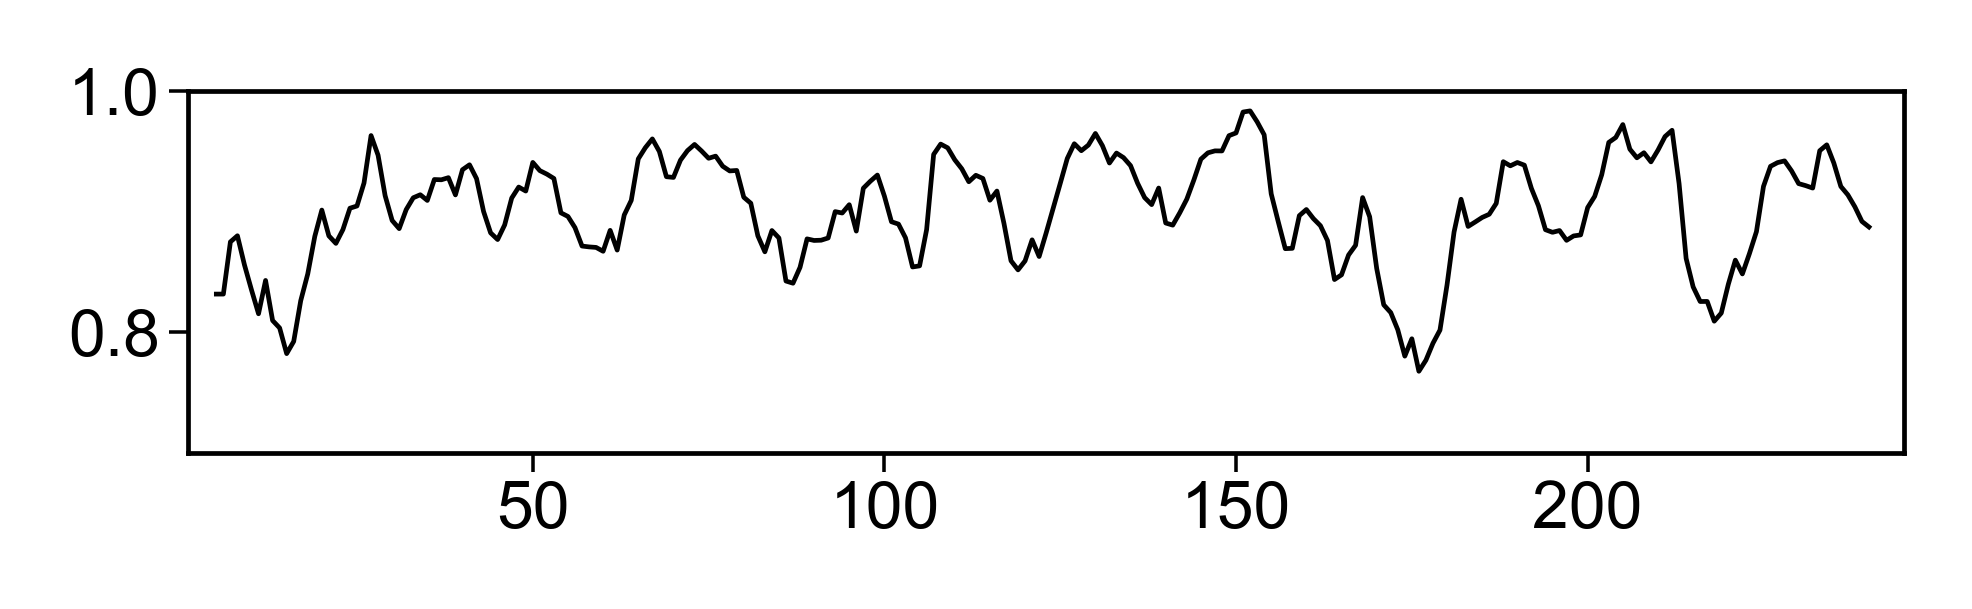

In [10]:
plt.figure(figsize=(3, 1), dpi=340)
ax = plt.gca()

# plot each window at its centre
centres = np.arange(WINDOW_SIZE // 2, WINDOW_SIZE // 2 + len(local_rg_ratio))
ax.plot(centres, local_rg_ratio, color='k', lw=0.5)

ax.set_ylim([0.7, 1])
ax.set_xlim([1, 245])
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig('figures/figure_S3C_local_rg.pdf')
plt.savefig('figures/figure_S3C_local_rg.png', dpi=340)
plt.show()

## Differences from the published figure

* **Assembly and labelling.** The published Figure S3 was assembled in a vector graphics editor from the three panel exports: the A/B/C letters, the shared "DDX4 NTD" residue axis, the y-axis labels, the "Helicity"/"beta-sheet" and "phi angle"/"psi angle" text, and the "Less RC"/"More RC" arrows on the right-hand side were all added there. The curves and the data are what this notebook produces.
* **Panel A subregion shading.** The original notebook had a `SHOW_SUBREGIONS` flag that shaded four helical regions (residues 11-18, 171-183, 195-203 and 215-222) in pale blue, and wrote a separate PDF when set. The published panel is the unshaded version, which is what is reproduced here.
* **Window centring in panel C.** The original plotted the sliding-window ratio starting at index `window_size/2` and running to `window_size/2 + len(values)`, which is what this notebook does - each point sits at the centre of its window. The behaviour is unchanged; it is just made explicit.
* **Number of windows.** The original iterated over `len(sequence) + 1 - window_size` using a hard-coded copy of the DDX4 sequence. This notebook takes the residue count from the trajectory itself, which is equivalent but removes the duplicated sequence string.
* **Self-Hellinger analysis.** The original notebook also computed a split-half "self" Hellinger distance (each ensemble against itself, first half versus second half) as a sampling-quality control, and wrote `self_hellinger.pdf`. That analysis does not appear in the published figure and is not reproduced here.